# Hito 5 — Comparación de Baseline y SVM

**Proyecto 1 de Innovación Tecnológica · Maestría en Inteligencia Artificial Aplicada · Universidad Icesi**

Este notebook muestra el flujo de validación cruzada multietiqueta sobre 90 características acústicas: preparación de etiquetas, escalado dentro de cada fold, entrenamiento del baseline y los tres kernels SVM, y evaluación agregada por grabación. Se excluye `test` en todo el análisis.

El límite SVM por defecto es **5.000 clips por fold**. Puedes cambiar `SVM_MAX_TRAIN_SAMPLES` a `None` en la celda de configuración para utilizar todos los clips del fold (~14.000). Ese modo puede requerir bastante más tiempo. El baseline siempre usa todo el fold.

## Paso 1 — Imports, rutas y configuración

Se fija la semilla para repetir el submuestreo aleatorio, se reutilizan los cinco folds ya asignados por autor, y se establece el límite configurable de entrenamiento para los SVM. El límite solo se aplica al SVM, no al baseline.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.metrics import compute_metrics
from src.training.hito5_baseline_svm import (
    aggregate_by_recording,
    build_multilabel_matrix,
    load_feature_columns,
    subsample_train,
)

FEATURES_CSV = PROJECT_ROOT / "src" / "data" / "features" / "features.csv"
OUT_DIR = PROJECT_ROOT / "experiments" / "results" / "hito4_5" / "supervised"
SEED = 42
FOLDS = [f"fold{i}" for i in range(5)]
MODELS = ["baseline_logreg", "svm_linear", "svm_rbf", "svm_poly"]
SVM_MAX_TRAIN_SAMPLES = 5000  # Cambia a None para usar el fold de entrenamiento completo.

if SVM_MAX_TRAIN_SAMPLES is not None and SVM_MAX_TRAIN_SAMPLES < 1:
    raise ValueError("SVM_MAX_TRAIN_SAMPLES debe ser positivo o None.")

print(f"Límite SVM por fold: {SVM_MAX_TRAIN_SAMPLES or 'sin límite (fold completo)'}")
print(f"Semilla de submuestreo: {SEED}")

Límite SVM por fold: 5000
Semilla de submuestreo: 42


## Paso 2 — Cargar datos y construir las etiquetas multietiqueta

Cada clip se representa mediante un vector binario de 16 posiciones. Una especie vale 1 si aparece en `primary_label` o en `secondary` y pertenece al subconjunto. Esta etiqueta se usa para entrenamiento supervisado, no como característica de entrada.

In [2]:
feature_columns = load_feature_columns()
df = pd.read_csv(FEATURES_CSV)
df = df.loc[df["partition"] != "test"].reset_index(drop=True)
species = sorted(df["primary_label"].unique().tolist())

X_all = df[feature_columns].to_numpy(dtype=np.float64)
Y_all = build_multilabel_matrix(df, species)
split_all = df["split"].to_numpy()
recording_all = df["recording_id"].to_numpy()

print(f"Clips train + val: {len(df):,}")
print(f"Características acústicas: {len(feature_columns)}")
print(f"Especies: {len(species)}")
print(f"Forma de X: {X_all.shape}; forma de Y: {Y_all.shape}")
print("Clips por fold:")
display(df["split"].value_counts().sort_index().rename("clips").to_frame())

Clips train + val: 17,893
Características acústicas: 90
Especies: 16
Forma de X: (17893, 90); forma de Y: (17893, 16)
Clips por fold:


,clips
split,
fold0,3435
fold1,3540
fold2,3658
fold3,3663
fold4,3597


## Paso 3 — Validación cruzada y escalado sin fuga

En cada vuelta, un fold completo se reserva para validación y los otros cuatro forman entrenamiento. El `StandardScaler` se ajusta solo con entrenamiento y luego transforma ambos conjuntos. El submuestreo SVM ocurre después del escalado y solo dentro del entrenamiento; la validación nunca se submuestrea.

## Paso 4 — Entrenar baseline y kernels SVM por fold

El baseline es regresión logística One-vs-Rest con pesos balanceados y umbral 0,5. Cada SVM (lineal, RBF, polinomial de grado 3) también usa One-vs-Rest y pesos balanceados; sus scores vienen de `decision_function` y el umbral es 0. La función `subsample_train` usa muestreo aleatorio sin reemplazo y conserva todos los datos cuando el tope es `None`.

Para cada modelo se guardan las métricas por fold y el número real de clips usados para entrenarlo.

In [3]:
fold_rows = []
per_class_rows = []

for fold in FOLDS:
    fold_start = time.time()
    val_mask = split_all == fold
    train_mask = (~val_mask) & np.isin(split_all, FOLDS)

    X_train, Y_train = X_all[train_mask], Y_all[train_mask]
    X_val, Y_val = X_all[val_mask], Y_all[val_mask]
    recording_val = recording_all[val_mask]

    scaler = StandardScaler().fit(X_train)
    X_train_scaled = scaler.transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    for model_name in MODELS:
        if model_name == "baseline_logreg":
            X_model, Y_model = X_train_scaled, Y_train
            classifier = OneVsRestClassifier(
                LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)
            )
            threshold = 0.5
        else:
            kernel = model_name.removeprefix("svm_")
            X_model, Y_model, _ = subsample_train(
                X_train_scaled,
                Y_train,
                np.arange(len(X_train_scaled)),
                SVM_MAX_TRAIN_SAMPLES,
                SEED,
            )
            classifier = OneVsRestClassifier(
                SVC(
                    kernel=kernel,
                    degree=3,
                    class_weight="balanced",
                    random_state=SEED,
                )
            )
            threshold = 0.0

        classifier.fit(X_model, Y_model)
        if model_name == "baseline_logreg":
            scores_val = classifier.predict_proba(X_val_scaled)
        else:
            scores_val = classifier.decision_function(X_val_scaled)

        predictions_val = (scores_val >= threshold).astype(int)
        aggregate_scores, aggregate_true = aggregate_by_recording(
            recording_val, scores_val, Y_val
        )
        aggregate_predictions, _ = aggregate_by_recording(
            recording_val, predictions_val, Y_val
        )
        aggregate_predictions = (aggregate_predictions >= 1).astype(int)

        metrics = compute_metrics(
            aggregate_true,
            aggregate_predictions,
            y_prob=aggregate_scores,
            class_names=None,
        )
        per_class_f1 = f1_score(
            aggregate_true, aggregate_predictions, average=None, zero_division=0
        )
        fold_rows.append(
            {
                "fold": fold,
                "model": model_name,
                "n_train_clips": int(len(X_train)),
                "n_model_train_clips": int(len(X_model)),
                "n_val_clips": int(len(X_val)),
                "n_val_recordings": int(len(aggregate_true)),
                "accuracy": metrics["accuracy"],
                "f1_macro": metrics["f1_macro"],
                "precision_macro": metrics["precision_macro"],
                "recall_macro": metrics["recall_macro"],
                "roc_auc_macro": metrics.get("roc_auc_macro"),
                "cmap": metrics.get("cmap"),
            }
        )
        per_class_rows.extend(
            {
                "fold": fold,
                "model": model_name,
                "species": species[index],
                "f1": float(value),
            }
            for index, value in enumerate(per_class_f1)
        )
        print(
            f"[{fold}] {model_name:16s} | "
            f"n_train={len(X_model):,} | "
            f"F1-macro={metrics['f1_macro']:.3f} | "
            f"ROC-AUC={metrics.get('roc_auc_macro', float('nan')):.3f}"
        )

    print(f"Tiempo total del fold {fold}: {time.time() - fold_start:.1f} s")

cv_scores = pd.DataFrame(fold_rows)
per_class_metrics = pd.DataFrame(per_class_rows)
assert len(cv_scores) == len(FOLDS) * len(MODELS)

[fold0] baseline_logreg  | n_train=14,458 | F1-macro=0.294 | ROC-AUC=0.893


[fold0] svm_linear       | n_train=5,000 | F1-macro=0.282 | ROC-AUC=0.875


[fold0] svm_rbf          | n_train=5,000 | F1-macro=0.426 | ROC-AUC=0.892


[fold0] svm_poly         | n_train=5,000 | F1-macro=0.374 | ROC-AUC=0.838
Tiempo total del fold fold0: 80.2 s


[fold1] baseline_logreg  | n_train=14,353 | F1-macro=0.306 | ROC-AUC=0.892


[fold1] svm_linear       | n_train=5,000 | F1-macro=0.292 | ROC-AUC=0.880


... (10 outputs left out)

[fold4] baseline_logreg  | n_train=14,296 | F1-macro=0.295 | ROC-AUC=0.891


[fold4] svm_linear       | n_train=5,000 | F1-macro=0.286 | ROC-AUC=0.877


[fold4] svm_rbf          | n_train=5,000 | F1-macro=0.445 | ROC-AUC=0.893


[fold4] svm_poly         | n_train=5,000 | F1-macro=0.387 | ROC-AUC=0.846
Tiempo total del fold fold4: 71.7 s


## Paso 5 — Agregar métricas, guardar resultados y comparar modelos

Las métricas se calculan por grabación: los scores de clips de una misma grabación se agregan tomando el máximo por especie. Se calcula promedio y desviación estándar entre los cinco folds. `n_model_train_clips` permite comprobar que el baseline usa el fold completo y que el límite seleccionado aplica a SVM.

In [4]:
metric_columns = [
    "accuracy", "f1_macro", "precision_macro", "recall_macro", "roc_auc_macro"
]
summary = cv_scores.groupby("model")[metric_columns].agg(["mean", "std"]).round(4)
summary_table = summary.copy()
summary_table.columns = [f"{metric}_{stat}" for metric, stat in summary_table.columns]
summary_table = summary_table.rename_axis("Modelo").reset_index()

config = {
    "seed": SEED,
    "folds": FOLDS,
    "models": MODELS,
    "class_weight": "balanced",
    "svm_max_train_samples_per_fold": SVM_MAX_TRAIN_SAMPLES,
    "svm_uses_full_fold": SVM_MAX_TRAIN_SAMPLES is None,
    "threshold_baseline": 0.5,
    "threshold_svm_decision_function": 0.0,
    "n_species": len(species),
    "species": species,
}
OUT_DIR.mkdir(parents=True, exist_ok=True)
cv_scores.to_csv(OUT_DIR / "cv_scores_by_fold.csv", index=False)
per_class_metrics.to_csv(OUT_DIR / "per_class_metrics.csv", index=False)
summary_json = {
    model: {
        metric: {
            "mean": float(summary.loc[model, (metric, "mean")]),
            "std": float(summary.loc[model, (metric, "std")]),
        }
        for metric in metric_columns
    }
    for model in summary.index
}
with (OUT_DIR / "cv_summary.json").open("w", encoding="utf-8") as file:
    json.dump({"config": config, "summary_by_model": summary_json}, file, indent=2, ensure_ascii=False)
with (OUT_DIR / "config.json").open("w", encoding="utf-8") as file:
    json.dump(config, file, indent=2, ensure_ascii=False)

print("Promedio ± desviación estándar entre folds:")
display(summary_table.style.format(precision=4))
print("Tamaño real de entrenamiento por modelo y fold:")
display(cv_scores.pivot(index="fold", columns="model", values="n_model_train_clips"))

Promedio ± desviación estándar entre folds:


,Modelo,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,roc_auc_macro_mean,roc_auc_macro_std
0,baseline_logreg,0.0250,0.0044,0.2987,0.0065,0.1854,0.0048,0.8831,0.0047,0.8941,0.0052
1,svm_linear,0.0195,0.0023,0.2884,0.0064,0.1785,0.0053,0.8724,0.0063,0.8803,0.0056
2,svm_poly,0.1791,0.0115,0.3870,0.0170,0.2957,0.0124,0.5863,0.0258,0.8473,0.0065
3,svm_rbf,0.1969,0.0246,0.4543,0.0205,0.3439,0.0208,0.7061,0.0113,0.8939,0.0019


Tamaño real de entrenamiento por modelo y fold:


model,baseline_logreg,svm_linear,svm_poly,svm_rbf
fold,,,,
fold0,14458,5000,5000,5000
fold1,14353,5000,5000,5000
fold2,14235,5000,5000,5000
fold3,14230,5000,5000,5000
fold4,14296,5000,5000,5000


## Paso 6 — Gráficas de comparación

Se visualizan Macro-F1 y ROC-AUC por modelo. Las barras de error representan desviación estándar entre folds. La figura de tamaño de entrenamiento hace explícita la diferencia de datos entre baseline y SVM.

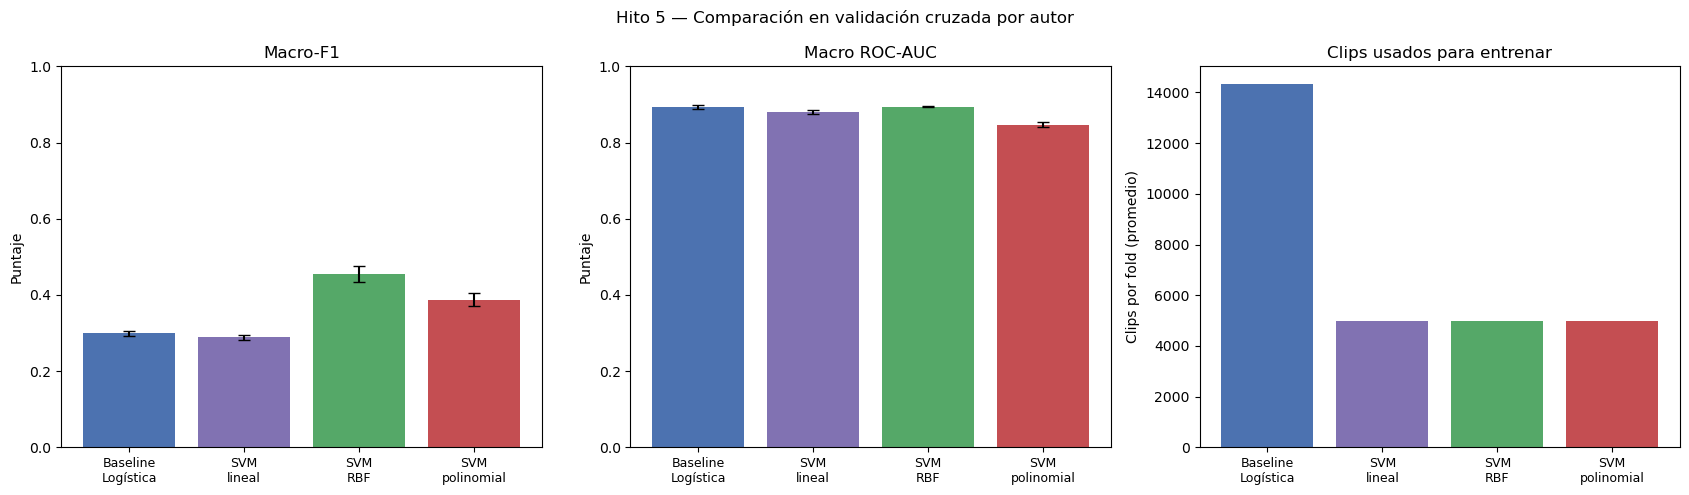

In [5]:
model_order = ["baseline_logreg", "svm_linear", "svm_rbf", "svm_poly"]
model_labels = ["Baseline\nLogística", "SVM\nlineal", "SVM\nRBF", "SVM\npolinomial"]
colors = ["#4c72b0", "#8172b2", "#55a868", "#c44e52"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metric, title in zip(
    axes[:2], ["f1_macro", "roc_auc_macro"], ["Macro-F1", "Macro ROC-AUC"]
):
    means = [summary.loc[model, (metric, "mean")] for model in model_order]
    stds = [summary.loc[model, (metric, "std")] for model in model_order]
    ax.bar(model_labels, means, yerr=stds, capsize=4, color=colors)
    ax.set_title(title)
    ax.set_ylabel("Puntaje")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelsize=9)

train_means = cv_scores.groupby("model")["n_model_train_clips"].mean().reindex(model_order)
axes[2].bar(model_labels, train_means, color=colors)
axes[2].set_title("Clips usados para entrenar")
axes[2].set_ylabel("Clips por fold (promedio)")
axes[2].tick_params(axis="x", labelsize=9)
fig.suptitle("Hito 5 — Comparación en validación cruzada por autor")
fig.tight_layout()
plt.show()

## Paso 7 — Conclusiones respaldadas por la ejecución

La conclusión se genera desde las métricas de los cinco folds de esta corrida. Los resultados históricos del reporte usaban 1.500 clips por SVM; si cambiaste `SVM_MAX_TRAIN_SAMPLES`, esta celda refleja la nueva ejecución y no debe mezclarse con los valores históricos.

In [6]:
best_f1_model = summary["f1_macro"]["mean"].idxmax()
best_auc_model = summary["roc_auc_macro"]["mean"].idxmax()

def format_mean_std(model, metric):
    mean = summary.loc[model, (metric, "mean")]
    std = summary.loc[model, (metric, "std")]
    return f"{mean:.3f} ± {std:.3f}"

print(f"Configuración SVM: {SVM_MAX_TRAIN_SAMPLES or 'fold completo'} clips máximos por fold.")
print(
    f"Mejor Macro-F1: {best_f1_model} ({format_mean_std(best_f1_model, 'f1_macro')}); "
    f"mejor ROC-AUC: {best_auc_model} ({format_mean_std(best_auc_model, 'roc_auc_macro')})."
)
print(
    "Baseline: Macro-F1 " + format_mean_std("baseline_logreg", "f1_macro") +
    ", ROC-AUC " + format_mean_std("baseline_logreg", "roc_auc_macro") + "."
)
print(
    "SVM RBF: Macro-F1 " + format_mean_std("svm_rbf", "f1_macro") +
    ", ROC-AUC " + format_mean_std("svm_rbf", "roc_auc_macro") + "."
)
if SVM_MAX_TRAIN_SAMPLES is not None:
    print(
        "Advertencia metodológica: baseline y SVM se entrenaron con cantidades distintas; "
        "la comparación no aísla únicamente el efecto del kernel. Para una comparación más pareja, "
        "ejecuta de nuevo con SVM_MAX_TRAIN_SAMPLES = None."
    )

Configuración SVM: 5000 clips máximos por fold.
Mejor Macro-F1: svm_rbf (0.454 ± 0.021); mejor ROC-AUC: baseline_logreg (0.894 ± 0.005).
Baseline: Macro-F1 0.299 ± 0.006, ROC-AUC 0.894 ± 0.005.
SVM RBF: Macro-F1 0.454 ± 0.021, ROC-AUC 0.894 ± 0.002.
Advertencia metodológica: baseline y SVM se entrenaron con cantidades distintas; la comparación no aísla únicamente el efecto del kernel. Para una comparación más pareja, ejecuta de nuevo con SVM_MAX_TRAIN_SAMPLES = None.
